In [6]:
import numpy as np
import pandas as pd
import datetime as dt
from pylab import mpl, plt
import seaborn as sns

In [8]:
plt.style.use('seaborn-v0_8')
mpl.rcParams['font.family'] = 'serif'
%matplotlib inline

In [18]:
raw = pd.read_csv("/Users/nicolai/Desktop/Koding/CSV_files/tr_eikon_eod_data.csv")
symbol = 'AAPL.O'
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1972 entries, 0 to 1971
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1972 non-null   object 
 1   AAPL.O  1972 non-null   float64
 2   MSFT.O  1972 non-null   float64
 3   INTC.O  1972 non-null   float64
 4   AMZN.O  1972 non-null   float64
 5   GS.N    1972 non-null   float64
 6   SPY     1972 non-null   float64
 7   .SPX    1972 non-null   float64
 8   .VIX    1972 non-null   float64
 9   EUR=    1972 non-null   float64
 10  XAU=    1972 non-null   float64
 11  GDX     1972 non-null   float64
 12  GLD     1972 non-null   float64
dtypes: float64(12), object(1)
memory usage: 200.4+ KB


In [24]:
data = (pd.DataFrame(raw[symbol]).dropna())
data.index = pd.date_range(
    start="2010-01-04",
    periods=len(data),
    freq="B"
)

data

,AAPL.O
2010-01-04,30.572827
2010-01-05,30.625684
2010-01-06,30.138541
2010-01-07,30.082827
2010-01-08,30.282827
...,...
2017-07-19,156.410000
2017-07-20,157.410000
2017-07-21,163.050000
2017-07-24,166.720000


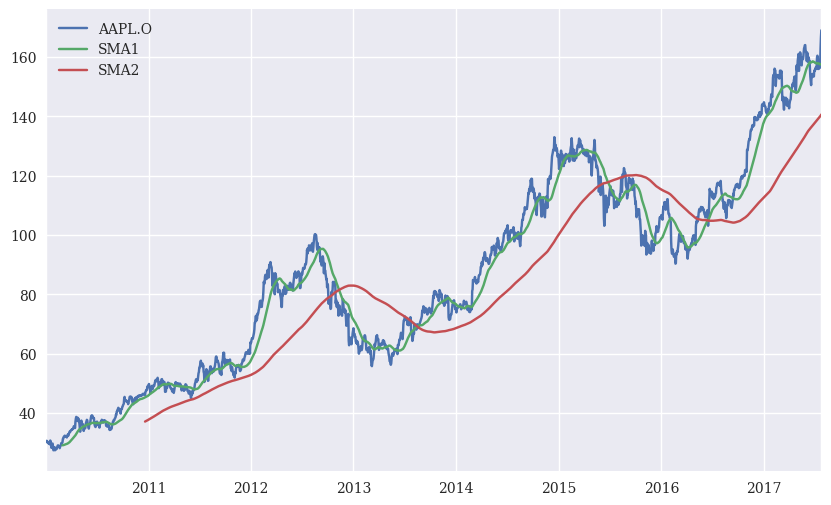

In [25]:
SMA1 = 42
SMA2 = 252
data['SMA1'] = data[symbol].rolling(SMA1).mean()
data['SMA2'] = data[symbol].rolling(SMA2).mean()
data.plot(figsize = (10,6));

In [34]:
data.dropna(inplace = True)
data['position'] = np.where(data['SMA1'] >data['SMA2'], 1, -1)
data.tail()

,AAPL.O,SMA1,SMA2,Position,returns,position
2017-07-19,156.41,157.610952,139.862520,1,-0.004402,1
2017-07-20,157.41,157.514286,140.028472,1,0.006373,1
2017-07-21,163.05,157.517619,140.221210,1,0.035203,1
2017-07-24,166.72,157.597857,140.431528,1,0.022259,1
2017-07-25,169.04,157.717857,140.651766,1,0.013820,1


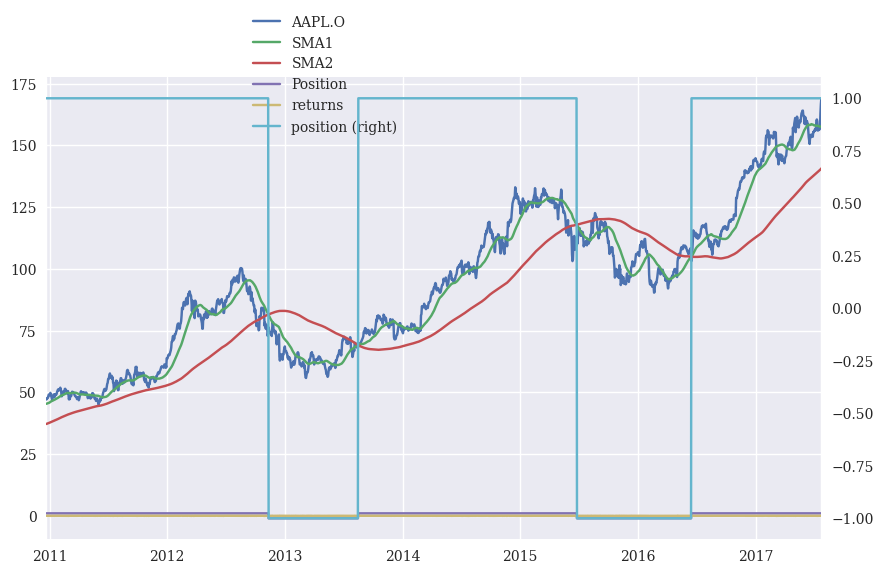

In [35]:
ax = data.plot(secondary_y = 'position', figsize = (10,6))
ax.get_legend().set_bbox_to_anchor((0.25, 0.85));             

In [37]:
data['returns'] = np.log(data[symbol] / data[symbol].shift(1))
data['strategy'] = data['position'].shift(1) * data['returns']
data.dropna(inplace = True)
data.round(4).head()

,AAPL.O,SMA1,SMA2,Position,returns,position,strategy
2010-12-23,47.3271,45.4126,37.2525,1,0.0052,1,0.0052
2010-12-24,47.7142,45.4661,37.3223,1,0.0081,1,0.0081
2010-12-27,47.6757,45.5226,37.3921,1,-0.0008,1,-0.0008
2010-12-28,48.0171,45.5821,37.4625,1,0.0071,1,0.0071
2010-12-29,48.9221,45.6718,37.5375,1,0.0187,1,0.0187


In [38]:
np.exp(data[['returns', 'strategy']].sum())

returns     3.590379
strategy    5.193925
dtype: float64

In [39]:
data[['returns', 'strategy']].std()*252**0.5

returns     0.252896
strategy    0.252714
dtype: float64

In [52]:
print((np.exp(data['returns'].sum())/np.exp(data['strategy'].sum()))*100)

69.12650497504205


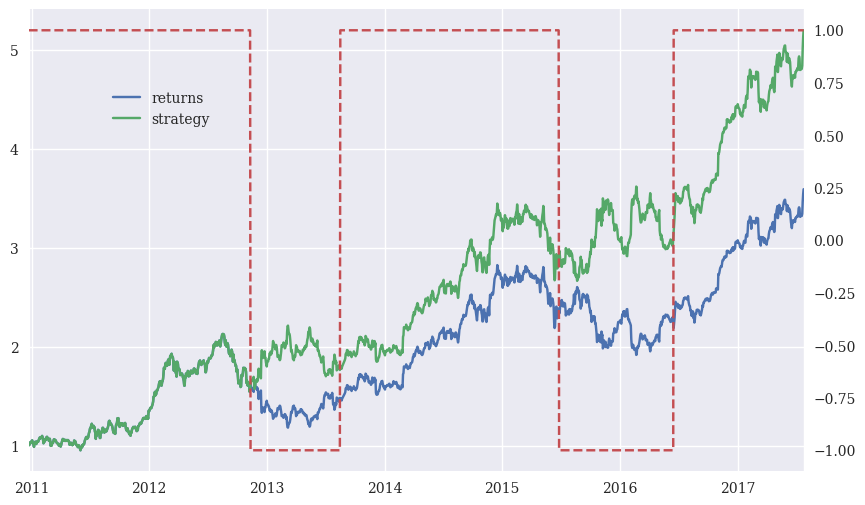

In [53]:
ax = data[['returns', 'strategy']].cumsum().apply(np.exp).plot(figsize = (10,6))
data['position'].plot(ax = ax, secondary_y = 'position', style = '--')
ax.get_legend().set_bbox_to_anchor((0.25, 0.85));

In [58]:
from itertools import product

sma1 = range(20, 61, 4)
sma2 = range(180, 281, 10)

results = pd.DataFrame()
for SMA1, SMA2 in product(sma1, sma2):
    data = pd.DataFrame(raw[symbol])
    data.dropna(inplace=True)
    data['returns'] = np.log(data[symbol] / data[symbol].shift(1))
    data['SMA1'] = data[symbol].rolling(SMA1).mean()
    data['SMA2'] = data[symbol].rolling(SMA2).mean()
    data.dropna(inplace=True)
    data['position'] = np.where(data['SMA1'] > data['SMA2'], 1, -1)
    data['strategy'] = data['position'].shift(1) * data['returns']
    data.dropna(inplace=True)
    perf = np.exp(data[['returns', 'strategy']].sum())
    
    # Replace append() with pd.concat()
    new_row = pd.DataFrame({
        'SMA1': [SMA1], 
        'SMA2': [SMA2],
        'market': [perf['returns']], 
        'strategy': [perf['strategy']],
        'out': [perf['strategy'] - perf['returns']]
    })
    results = pd.concat([results, new_row], ignore_index=True)

In [65]:
results.info()
results.sort_values('out', ascending = False).head(7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SMA1      121 non-null    int64  
 1   SMA2      121 non-null    int64  
 2   market    121 non-null    float64
 3   strategy  121 non-null    float64
 4   out       121 non-null    float64
dtypes: float64(3), int64(2)
memory usage: 4.9 KB


,SMA1,SMA2,market,strategy,out
56,40,190,4.246631,6.552273,2.305642
39,32,240,3.694406,5.989309,2.294903
59,40,220,3.853897,5.976137,2.122240
46,36,200,3.721010,5.834923,2.113913
55,40,180,4.177810,6.262625,2.084815
70,44,220,3.853897,5.908175,2.054279
101,56,200,3.721010,5.770906,2.049896


In [69]:
symbol = '.SPX'
data = pd.DataFrame(raw[symbol])
lags = 5
cols = []
for lag in range(1, lags + 1):
    col = 'lag_{}'.format(lag)
    data[col] = data[symbol].shift(lag)
    cols.append(col)

In [75]:
data.head(7)
data.dropna(inplace = True)
data

,.SPX,lag_1,lag_2,lag_3,lag_4,lag_5
5,1146.98,1144.98,1141.69,1137.14,1136.52,1132.99
6,1136.22,1146.98,1144.98,1141.69,1137.14,1136.52
7,1145.68,1136.22,1146.98,1144.98,1141.69,1137.14
8,1148.46,1145.68,1136.22,1146.98,1144.98,1141.69
9,1136.03,1148.46,1145.68,1136.22,1146.98,1144.98
...,...,...,...,...,...,...
1967,2557.15,2569.13,2564.98,2575.21,2562.10,2561.26
1968,2560.40,2557.15,2569.13,2564.98,2575.21,2562.10
1969,2581.07,2560.40,2557.15,2569.13,2564.98,2575.21
1970,2572.83,2581.07,2560.40,2557.15,2569.13,2564.98


In [84]:
raw.columns
symbol = 'EUR='
data = pd.DataFrame(raw[symbol])
data['returns'] = np.log(data/data.shift(1))
data.dropna(inplace = True)
data['direction'] = np.sign(data ['returns'].astype(int))

data.head()

,EUR=,returns,direction
1,1.4368,-0.002988,0
2,1.4412,0.003058,0
3,1.4318,-0.006544,0
4,1.4412,0.006544,0
5,1.4513,0.006984,0


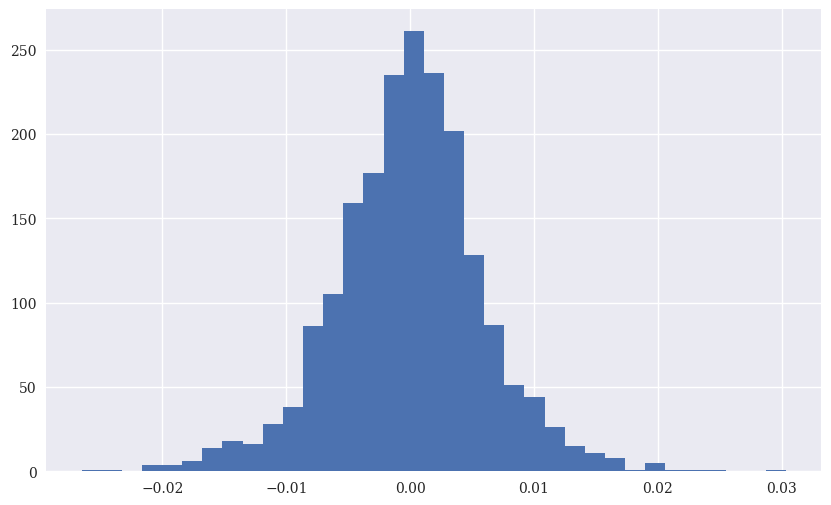

In [85]:
data['returns'].hist(bins = 35, figsize = (10,6));

In [94]:
lags = 2
def create_lags(data):
    global cols
    cols = []
    for lag in range(1, lags  + 1):
        col = 'lag_{}'.format(lag)
        data[col] = data['returns'].shift(lag)
        cols.append(col)
create_lags(data)
data.dropna(inplace=True)
data.head()

,EUR=,returns,direction,lag_1,lag_2
9,1.4382,-0.008309,0,-0.000551,0.001103
10,1.4298,-0.005858,0,-0.008309,-0.000551
11,1.4101,-0.013874,0,-0.005858,-0.008309
12,1.4090,-0.000780,0,-0.013874,-0.005858
13,1.4137,0.003330,0,-0.000780,-0.013874


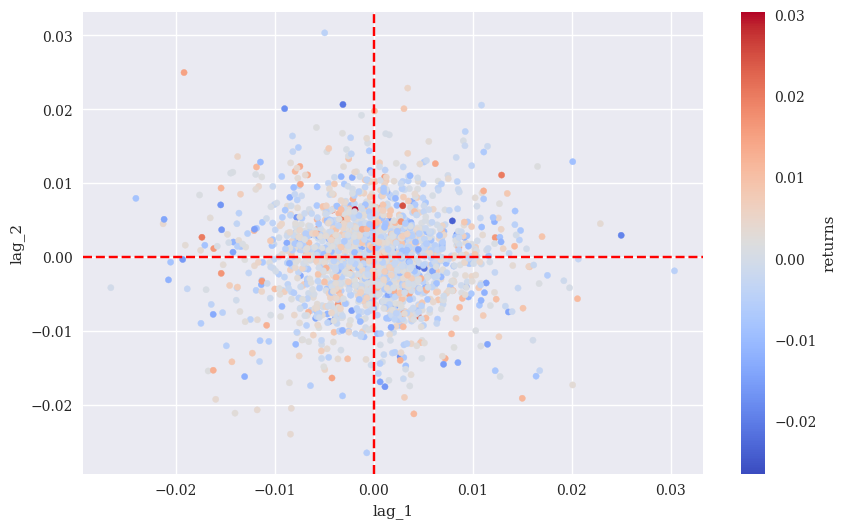

In [95]:
data.plot.scatter(x = 'lag_1', y = 'lag_2', c = 'returns',
                  cmap = 'coolwarm', figsize = (10,6), colorbar = True)
plt.axvline(0, c = 'r', ls = '--')
plt.axhline(0, c = 'r', ls = '--')

In [99]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

data['pos_ols_1'] = model.fit(data[cols], data['returns']).predict(data[cols])
data['pos_ols_2'] = model.fit(data[cols], data['direction']).predict(data[cols])

data[['pos_ols_1', 'pos_ols_2']].head()

,pos_ols_1,pos_ols_2
9,-0.000088,0.0
10,0.000022,0.0
11,-0.000124,0.0
12,0.000046,0.0
13,-0.000285,0.0


In [102]:
data[['pos_ols_1', 'pos_ols_2']] = np.where(
    data[['pos_ols_1', 'pos_ols_2']] > 0, 1, -1)
data[['pos_ols_1','pos_ols_2']].value_counts()

pos_ols_1  pos_ols_2
-1         -1           1614
 1         -1            349
Name: count, dtype: int64

In [107]:
(data[['pos_ols_1','pos_ols_2']].diff() != 0).sum()

pos_ols_1    677
pos_ols_2      1
dtype: int64

In [109]:
data['strat_ols_1'] = data['pos_ols_1'] * data['returns']
data['strat_ols_2'] = data['pos_ols_2'] * data['returns']
data[['returns', 'strat_ols_1', 'strat_ols_2']].sum().apply(np.exp)

returns        0.802924
strat_ols_1    1.319110
strat_ols_2    1.245448
dtype: float64

In [117]:
print((data['direction'] == data['pos_ols_1']).value_counts())
print((data['direction'] == data['pos_ols_2']).value_counts())

False    1963
Name: count, dtype: int64
False    1963
Name: count, dtype: int64


In [119]:
data[['returns', 'strat_ols_1', 'strat_ols_2']].cumsum().
    apply(np.exp).plot(figsize(10,6));

SyntaxError: invalid syntax (3096267181.py, line 1)